# Chapitre 9 - Cours 6 : méthodes formelles et tests aléatoires

Les cours précédents ont montré combien de choses peuvent mal tourner : messages perdus
ou retardés, pauses, horloges fausses, nœuds amnésiques. Comment savoir qu'un algorithme
et, surtout, son implémentation respectent leurs propriétés de sûreté **dans tous les
cas** ? Ce notebook, consacré à une section nouvelle de la 2e édition, construit un petit
**model checker** exhaustif, pratique l'**injection de fautes** et la **simulation
déterministe** sur le protocole de bail du cours 4. Il couvre la section *Formal Methods
and Randomized Testing* (*Model checking and specification languages*, *Fault
injection*, *Deterministic simulation testing*, encadré *The Power of Determinism*).

**Plan.**

1. Pourquoi tester à la main ne suffit pas : l'explosion des entrelacements.
2. Un model checker en 60 lignes.
3. L'injection de fautes.
4. La simulation déterministe.
5. La puissance du déterminisme.

In [1]:
import os
import subprocess
import sys
import time
from math import factorial

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

from ddia import distsys as ds
from ddia import distsys_verif as dv
from ddia.diagrams import Diagram
from ddia.plotting import (AMBER, GRAY, GREEN, INDIGO, LIGHT, ROSE, SKY, SLATE, TEAL, VIOLET,
                           annotate_bars, set_style, subtitle)
from ddia.requirements import plain_log_axis
from ddia.timelines import SpaceTime

set_style()
plt.rcParams["axes.titlepad"] = 16
pd.set_option("display.precision", 4)
pd.set_option("display.max_colwidth", 110)

## 1. Pourquoi tester à la main ne suffit pas (section *Formal Methods and Randomized Testing*)

À cause de la concurrence, des pannes partielles et des délais réseau, un système
distribué a un nombre **gigantesque** d'états possibles. Il faut que les propriétés
tiennent dans **chacun**, sans oublier de cas limite. Comptons seulement les ordres
possibles d'exécution (entrelacements) de $k$ processus de $s$ étapes chacun, sans même
ajouter de pannes : $\frac{(ks)!}{(s!)^k}$.

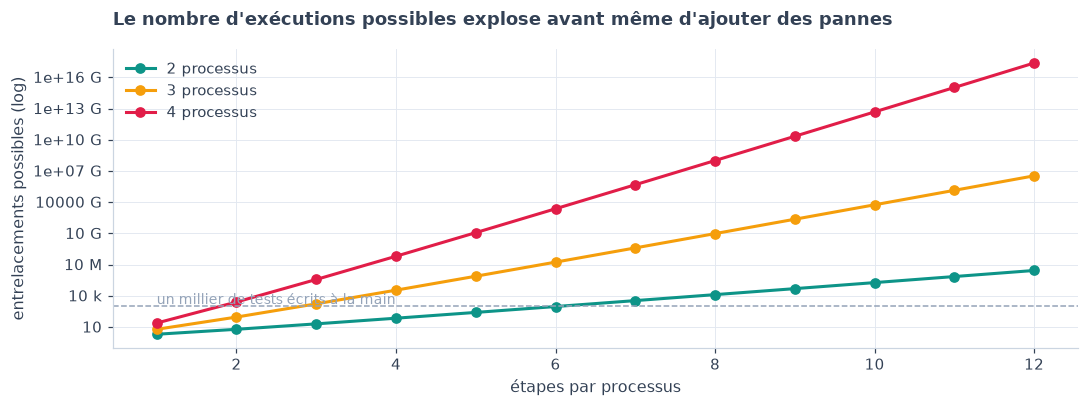

In [2]:
fig, ax = plt.subplots(figsize=(10, 3.8))
s_ = np.arange(1, 13)
for k, c in [(2, TEAL), (3, AMBER), (4, ROSE)]:
    ax.semilogy(s_, [factorial(k * s) / factorial(s) ** k for s in s_], "o-", color=c, label=f"{k} processus")
ax.axhline(1e3, color=GRAY, ls="--", lw=1); ax.text(1, 1.6e3, "un millier de tests écrits à la main", fontsize=9, color=GRAY)
plain_log_axis(ax, "y")
ax.set_xlabel("étapes par processus"); ax.set_ylabel("entrelacements possibles (log)")
ax.set_title("Le nombre d'exécutions possibles explose avant même d'ajouter des pannes")
ax.legend()
plt.tight_layout(); plt.show()

Trois processus de dix étapes ont déjà $5{,}5 \times 10^{12}$ entrelacements. Le livre
décrit deux familles de réponses, à **combiner** :

- la **vérification formelle** : décrire l'algorithme mathématiquement et prouver qu'il
  satisfait ses propriétés dans toutes les situations du modèle de système. Prouver
  l'algorithme ne garantit pas que l'implémentation soit correcte, mais l'analyse révèle
  des problèmes qui resteraient cachés longtemps en production, jusqu'au jour où une
  hypothèse (de temps, par exemple) est mise en défaut ;
- les **tests aléatoires** : tests fondés sur des propriétés, fuzzing, **simulation
  déterministe**, qui explorent une grande variété de situations. Amazon Web Services,
  FoundationDB ou TigerBeetle combinent ces techniques avec succès.

> **À retenir.** L'espace des exécutions d'un système distribué est trop grand pour des
> tests écrits à la main. On combine raisonnement formel (preuve, model checking) et
> exploration aléatoire massive.

## 2. Un model checker en 60 lignes (section *Model checking and specification languages*)

Un **model checker** vérifie qu'un **invariant** tient dans **tous** les états
accessibles d'un modèle de l'algorithme, en essayant systématiquement tout ce qui peut
arriver. Le modèle s'écrit dans un langage dédié (TLA+, Gallina, FizzBee...) qui permet de
se concentrer sur le comportement sans les détails d'implémentation. Notre version
(`dv.model_check`) tient en quelques lignes : un état initial, une fonction qui donne les
**successeurs** d'un état (avec le nom de l'action), un invariant, et un parcours en
**largeur** qui renvoie, en cas d'échec, le **plus court** chemin vers un état fautif.

**Échauffement : la mise à jour perdue.** Deux processus incrémentent un compteur partagé
en le lisant puis en écrivant la valeur lue plus un (`dv.counter_model`). Invariant :
quand les deux ont fini, le compteur vaut 2.

In [3]:
rows = []
for n_procs in (2, 3, 4):
    for atomic in (False, True):
        r = dv.model_check(*dv.counter_model(n_procs, atomic=atomic))
        rows.append(dict(processus=n_procs, incrément="atomique" if atomic else "lire puis écrire",
                         états=r.states, transitions=r.transitions, verdict="ok" if r.ok else "VIOLATION",
                         contre_exemple=" ; ".join(a for a, _ in r.path) if r.path else ""))
M = pd.DataFrame(rows)
M

,processus,incrément,états,transitions,verdict,contre_exemple
0,2,lire puis écrire,12,12,VIOLATION,p0 lit x=0 ; p1 lit x=0 ; p0 écrit x=1 ; p1 écrit x=1
1,2,atomique,4,4,ok,
2,3,lire puis écrire,70,89,VIOLATION,p0 lit x=0 ; p0 écrit x=1 ; p1 lit x=1 ; p2 lit x=1 ; p1 écrit x=2 ; p2 écrit x=2
3,3,atomique,8,12,ok,
4,4,lire puis écrire,648,946,VIOLATION,p0 lit x=0 ; p0 écrit x=1 ; p1 lit x=1 ; p1 écrit x=2 ; p2 lit x=2 ; p3 lit x=2 ; p2 écrit x=3 ; p3 écrit x=3
5,4,atomique,16,32,ok,


En quelques dizaines d'états, le model checker trouve le scénario de la **mise à jour
perdue** du chapitre 8 : les deux processus lisent 0, puis écrivent 1.
Avec un incrément atomique, l'invariant tient dans tous les états.

**Le protocole de bail du cours 4.** `dv.lease_model` modélise, à temps discret, deux
clients, un service de verrous et un stockage. Les actions sont : obtenir le bail
(`acquire`, si personne ne le détient ou s'il a expiré), le vérifier (`check`), écrire
(`write`), et faire avancer le temps d'une unité (`tick`). Le point clé : un `tick` peut
survenir **à tout moment**, en particulier entre `check` et `write`. C'est ainsi qu'un
model checker représente une pause de processus, sans qu'on ait à l'imaginer.
L'invariant (sûreté) : le stockage n'accepte jamais une écriture d'un jeton plus ancien
qu'un jeton déjà accepté, ni deux clients avec le même jeton. Vérifions quatre variantes.

In [4]:
variantes = {
    "sans jetons": dict(),
    "avec jetons": dict(fencing=True),
    "avec jetons, verrous amnésiques": dict(fencing=True, lock_crash=True, persist=False),
    "avec jetons, compteur sur disque": dict(fencing=True, lock_crash=True, persist=True),
}
res = {}
rows = []
for nom, kw in variantes.items():
    t0 = time.perf_counter()
    r = dv.model_check(*dv.lease_model(lease=2, t_max=5, **kw))
    res[nom] = r
    rows.append(dict(variante=nom, états=r.states, transitions=r.transitions, profondeur=r.depth,
                     verdict="ok" if r.ok else f"VIOLATION en {len(r.path)} actions",
                     durée_ms=(time.perf_counter() - t0) * 1e3))
pd.DataFrame(rows).set_index("variante")

,états,transitions,profondeur,verdict,durée_ms
variante,,,,,
sans jetons,434,614,8,VIOLATION en 8 actions,0.5161
avec jetons,940,1589,13,ok,1.2424
"avec jetons, verrous amnésiques",803,1170,7,VIOLATION en 7 actions,0.6283
"avec jetons, compteur sur disque",5220,10474,16,ok,8.1410


Sans jetons, le model checker exhibe le scénario du zombie en 8 actions ; avec jetons,
l'invariant tient dans tous les états accessibles ; si le service de verrous peut tomber
et redémarrer en oubliant son compteur, il trouve une violation même avec des jetons ; avec
un compteur sur disque, tout va bien. Dessinons les deux contre-exemples.

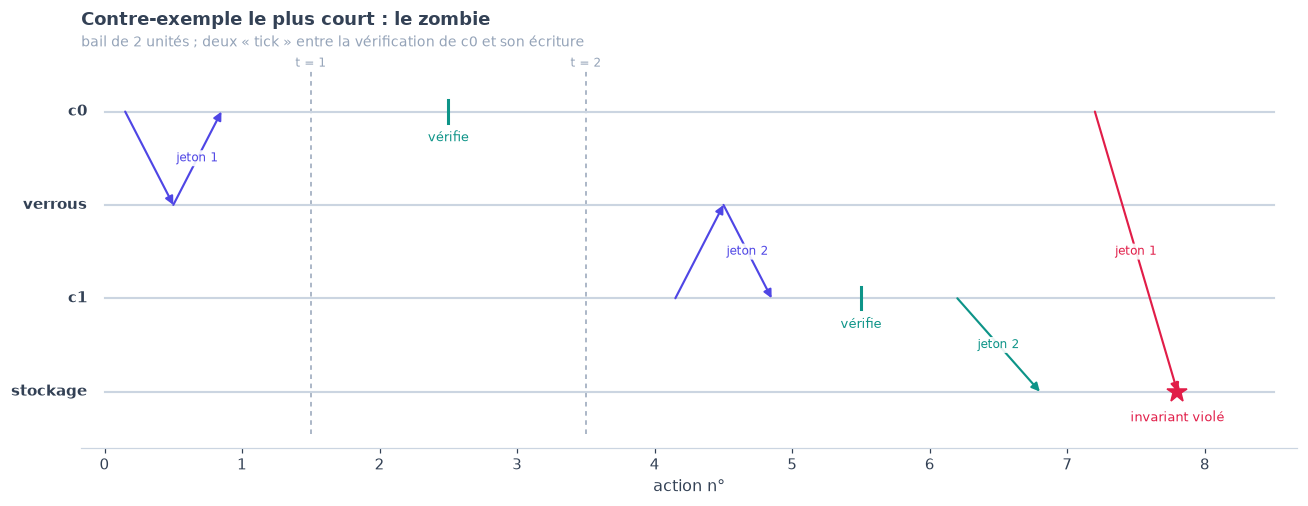

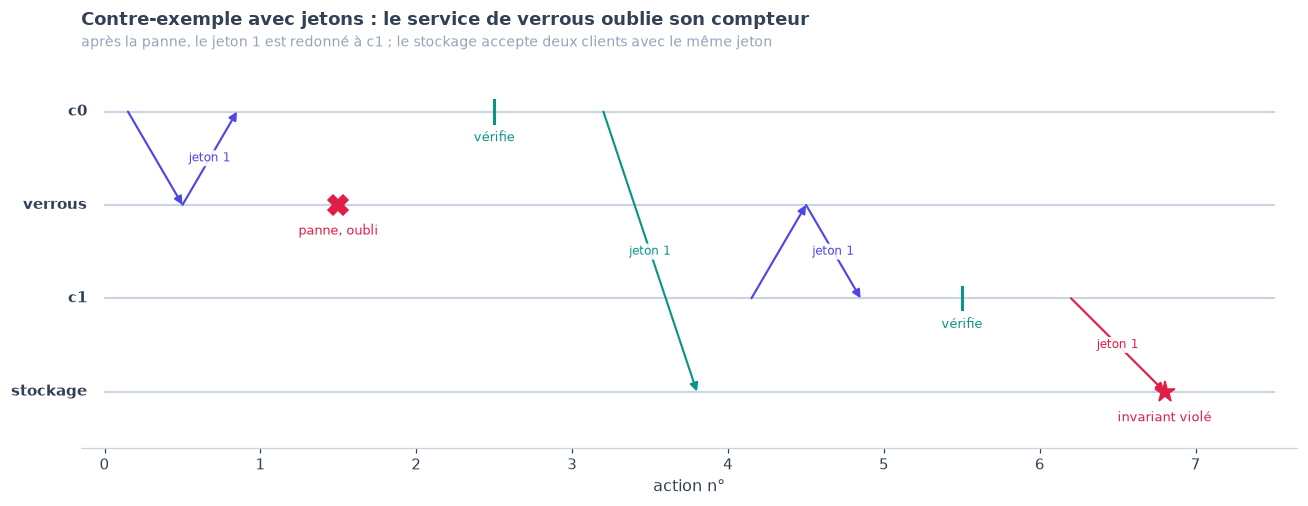

In [5]:
def dessine_chemin(path, titre, sous_titre):
    lanes = ["c0", "verrous", "c1", "stockage"]
    st = SpaceTime(lanes, t_max=len(path) + 0.5, width=12, title=titre, subtitle=sous_titre,
                   time_label="action n°", show_axis=True)
    for k, (action, state) in enumerate(path, start=1):
        x = k - 0.5
        if action == "tick":
            st.vline(x, f"t = {state[0]}")
        elif action.startswith("crash"):
            st.event("verrous", x, "panne, oubli", kind="crash")
        else:
            verbe, client = action.split()[:2]
            if verbe == "acquire":
                st.msg(client, x - 0.35, "verrous", x, "", color=INDIGO)
                st.msg("verrous", x, client, x + 0.35, action.split("(")[1].rstrip(")"), color=INDIGO)
            elif verbe == "check":
                st.event(client, x, "vérifie", kind="tick", color=TEAL)
            else:
                bad = state[6][2]
                st.msg(client, x - 0.3, "stockage", x + 0.3, action.split("(")[1].split(")")[0],
                       color=ROSE if bad else TEAL)
                if bad:
                    st.event("stockage", x + 0.3, "invariant violé", kind="star", color=ROSE)
    st.show()

dessine_chemin(res["sans jetons"].path, "Contre-exemple le plus court : le zombie",
               "bail de 2 unités ; deux « tick » entre la vérification de c0 et son écriture")
dessine_chemin(res["avec jetons, verrous amnésiques"].path, "Contre-exemple avec jetons : le service de verrous oublie son compteur",
               "après la panne, le jeton 1 est redonné à c1 ; le stockage accepte deux clients avec le même jeton")

Le premier chemin est exactement la figure du cours 4, trouvée **automatiquement** : c0
obtient le jeton 1 et vérifie son bail, le temps avance deux fois (la pause), c1 obtient
le jeton 2 et écrit, puis c0 écrit avec un jeton périmé. Le second montre qu'une hypothèse
implicite des jetons de clôture, la **monotonie** du générateur (cours 5), tombe si le
service de verrous redémarre sans son compteur.

**Les limites.** Un model checker ne **prouve** rien sur un espace d'états infini : on
borne le modèle (ici, le temps à `t_max` et un seul crash) et les bogues qui exigent des
exécutions plus longues passent inaperçus. Une preuve formelle couvrirait tous les états,
mais demande beaucoup plus d'efforts. Et la taille de l'espace grandit vite avec les
bornes :

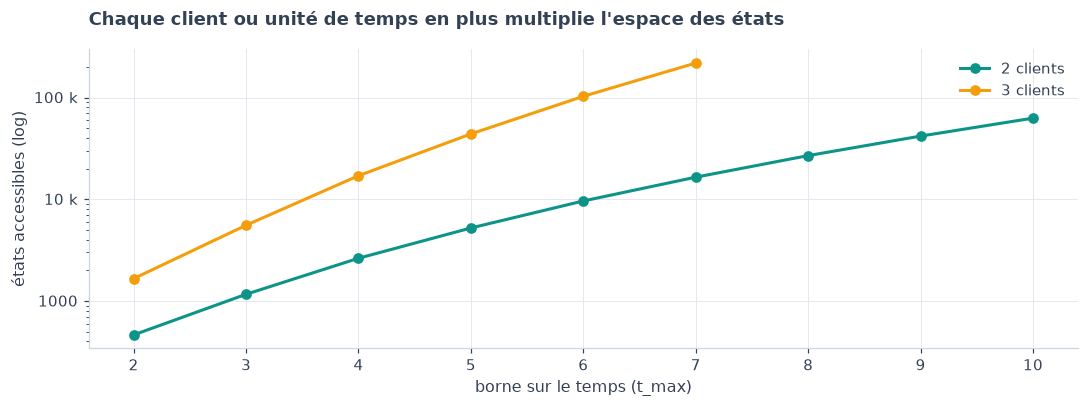

In [6]:
fig, ax = plt.subplots(figsize=(10, 3.8))
for nc, c in [(2, TEAL), (3, AMBER)]:
    tm = range(2, 11 if nc == 2 else 8)
    ax.semilogy(list(tm), [dv.model_check(*dv.lease_model(n_clients=nc, t_max=t, fencing=True, lock_crash=True)).states
                           for t in tm], "o-", color=c, label=f"{nc} clients")
plain_log_axis(ax, "y")
ax.set_xlabel("borne sur le temps (t_max)"); ax.set_ylabel("états accessibles (log)")
ax.set_title("Chaque client ou unité de temps en plus multiplie l'espace des états")
ax.legend()
plt.tight_layout(); plt.show()

Malgré ces limites, les model checkers offrent un bon équilibre entre facilité d'usage et
capacité à trouver des bogues non évidents : CockroachDB, TiDB, Kafka et bien d'autres
s'en servent, et TLA+ a révélé un risque de perte de données dans *viewstamped
replication*, dû à une ambiguïté de la description en prose. Revers de la médaille : le
model checker vérifie un **modèle**, pas le code, et les deux peuvent diverger ; vérifier
leur équivalence demande d'instrumenter l'implémentation.

> **À retenir.** Un model checker explore systématiquement tous les états d'un modèle
> borné et renvoie un contre-exemple minimal. Il trouve des bogues subtils (pauses,
> amnésie) mais vérifie un modèle, pas le code réel.

## 3. L'injection de fautes (section *Fault injection*)

Beaucoup de bogues ne se déclenchent que lors de pannes de machines ou de réseau.
L'**injection de fautes** consiste à provoquer ces pannes dans l'environnement d'un
système en marche et à observer son comportement : coupures réseau, plantages, disques
corrompus, processus en pause... Les tests tournent dans un environnement proche de la
production, voire **en** production (Netflix a popularisé l'idée avec Chaos Monkey ; on
parle alors d'**ingénierie du chaos**, chapitre 2). Des coordinateurs
décident quelles fautes injecter et quand ; des scripts les déclenchent (`kill` pour
tuer ou suspendre un processus, `umount` pour retirer un disque, des règles de pare-feu
pour couper le réseau). Ces outils étant fastidieux à assembler, on utilise souvent un
cadre comme **Jepsen**, remarquablement efficace pour trouver des bogues graves dans des
systèmes très utilisés.

Injectons des fautes aléatoires dans notre système de bail simulé
(`dv.run_lease_system` : trois clients qui prennent le bail et écrivent en boucle,
messages perdus à 2 %, et six fautes tirées au hasard parmi des pauses de clients et des
pannes du service de verrous), sur 200 scénarios et trois configurations.

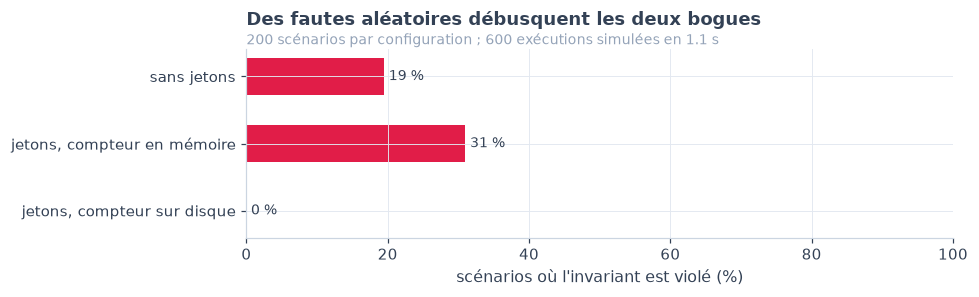

,scénarios_fautifs
configuration,
sans jetons,19.5
"jetons, compteur en mémoire",31.0
"jetons, compteur sur disque",0.0


In [7]:
configs = {"sans jetons": dict(fencing=False), "jetons, compteur en mémoire": dict(persist_counter=False),
           "jetons, compteur sur disque": dict()}
rows = []
t0 = time.perf_counter()
for nom, kw in configs.items():
    oks = [dv.run_lease_system(dv.random_faults(s), seed=s, **kw).ok for s in range(200)]
    rows.append(dict(configuration=nom, scénarios_fautifs=100 * (1 - np.mean(oks))))
duree = time.perf_counter() - t0
F = pd.DataFrame(rows).set_index("configuration")
fig, ax = plt.subplots(figsize=(9, 2.8))
ax.barh(F.index, F.scénarios_fautifs, color=[ROSE, ROSE, TEAL], height=0.55)
annotate_bars(ax, "{:.0f} %")
ax.invert_yaxis(); ax.set_xlim(0, 100)
ax.set_xlabel("scénarios où l'invariant est violé (%)"); ax.set_ylabel("")
ax.set_title("Des fautes aléatoires débusquent les deux bogues")
subtitle(ax, f"200 scénarios par configuration ; 600 exécutions simulées en {duree:.1f} s")
plt.tight_layout(); plt.show()
F.round(1)

Sans jetons, environ un scénario sur cinq aboutit à une écriture de zombie acceptée ; avec
des jetons mais un compteur en mémoire, les pannes du service de verrous suffisent à
produire des jetons réutilisés (près d'un scénario sur trois) ; avec un compteur sur disque, aucun des 200 scénarios ne
viole l'invariant (ce qui ne **prouve** pas son absence de bogue). L'injection de fautes
sur un vrai système a cependant un défaut : quand un test échoue, on ne contrôle pas
assez finement l'environnement pour **rejouer** exactement le même déroulement. C'est ce
que résout la simulation déterministe.

> **À retenir.** Injecter des pannes (réseau, plantages, pauses) dans un système qui
> tourne révèle les bogues de gestion des fautes ; des cadres comme Jepsen rendent la
> technique praticable.

## 4. La simulation déterministe (section *Deterministic simulation testing*)

La **simulation déterministe** (DST) explore l'espace des états comme un model checker,
mais en exécutant le **vrai code** plutôt qu'un modèle. Réseau, E/S et horloges sont
remplacés par des simulations qui laissent le simulateur décider de l'ordre exact des
événements, des délais et des pannes ; il peut ainsi parcourir bien plus de situations
que des tests écrits à la main. Surtout, quand un test échoue, on le **rejoue** à
l'identique, puisque tout dépend de la graine. C'est précisément ainsi qu'est construit
`ddia.sim`, utilisé depuis le début du chapitre. Vérifions la propriété de rejeu sur
l'empreinte (hachage) de la trace complète des messages.

In [8]:
faults = dv.random_faults(7)
rows = []
for k, seed in enumerate([7, 7, 7, 8]):
    r = dv.run_lease_system(faults, seed=seed)
    rows.append(dict(exécution=k + 1, graine=seed, messages=r.n_messages, écritures_acceptées=r.accepted,
                     empreinte_de_la_trace=r.digest))
pd.DataFrame(rows).set_index("exécution")

,graine,messages,écritures_acceptées,empreinte_de_la_trace
exécution,,,,
1,7,510,99,ec8e82ec983e0ed8
2,7,510,99,ec8e82ec983e0ed8
3,7,510,99,ec8e82ec983e0ed8
4,8,485,104,5cdcfad79ec077aa


Trois exécutions avec la graine 7 donnent la même trace, au bit près ; la graine 8 donne
une autre exécution. Le flux de travail d'un développeur devient : **chercher** une graine
qui viole l'invariant, la **réduire** au scénario le plus simple, la **rejouer** sous le
débogueur, corriger, puis vérifier des milliers de graines. Appliquons-le au bogue du
compteur en mémoire.

In [9]:
t0 = time.perf_counter()
seed, faults, res_f = dv.find_failing_seed(range(1000), persist_counter=False)
t_find = time.perf_counter() - t0
mini = dv.shrink_faults(faults, seed, persist_counter=False)
res_m = dv.run_lease_system(mini, seed=seed, persist_counter=False)
rejeu = dv.run_lease_system(mini, seed=seed, persist_counter=False)
print(f"graine fautive : {seed} (trouvée en {t_find * 1e3:.0f} ms) ; fautes : {len(faults)} -> {len(mini)} après réduction")
for f in mini:
    print("   ", f)
print(f"rejeu identique : {rejeu.digest == res_m.digest} ; première violation à t = {res_m.violations[0].t:.2f}")

graine fautive : 1 (trouvée en 3 ms) ; fautes : 6 -> 2 après réduction
    Fault(kind='crash_verrous', t=8.21, target='verrous', duration=0.59)
    Fault(kind='crash_verrous', t=29.02, target='verrous', duration=3.81)
rejeu identique : True ; première violation à t = 48.93


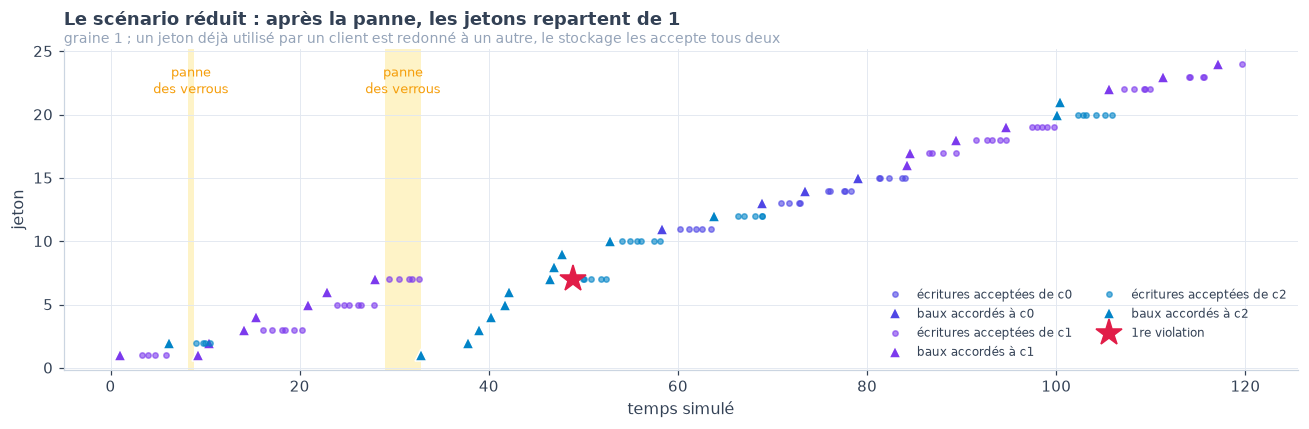

In [10]:
net = res_m.net
lock = net["verrous"]
fig, ax = plt.subplots(figsize=(12, 4))
for i, c in enumerate([INDIGO, VIOLET, SKY]):
    g = [x for x in lock.grants if x.client == f"c{i}"]
    w = [x for x in res_m.store.writes if x.client == f"c{i}" and x.accepted]
    ax.plot([x.t for x in w], [x.token for x in w], "o", ms=3.5, color=c, alpha=0.6, label=f"écritures acceptées de c{i}")
    ax.plot([x.t for x in g], [x.token for x in g], "^", ms=8, color=c, mec="white", label=f"baux accordés à c{i}")
for f in mini:
    if f.kind == "crash_verrous":
        ax.axvspan(f.t, f.t + f.duration, color=LIGHT[AMBER], lw=0)
        ax.text(f.t + f.duration / 2, ax.get_ylim()[1] * 0.95 if ax.get_ylim()[1] > 1 else 1, "panne\ndes verrous",
                ha="center", va="top", fontsize=8.5, color=AMBER)
    else:
        ax.axvspan(f.t, f.t + f.duration, color=LIGHT[GRAY], lw=0)
for v in res_m.violations[:1]:
    ax.plot(v.t, v.token, "*", ms=18, color=ROSE, zorder=5, label="1re violation")
ax.set_xlabel("temps simulé"); ax.set_ylabel("jeton")
ax.set_title("Le scénario réduit : après la panne, les jetons repartent de 1")
subtitle(ax, f"graine {seed} ; un jeton déjà utilisé par un client est redonné à un autre, le stockage les accepte tous deux")
ax.legend(fontsize=8, ncol=2, loc="lower right")
plt.tight_layout(); plt.show()

Le scénario réduit ne contient plus que la ou les pannes du service de verrous
nécessaires : après la panne, le compteur repart de 1, et dès qu'un jeton réattribué
atteint la valeur d'un jeton déjà utilisé par **un autre** client, le stockage accepte les
écritures des deux. (La réduction est imparfaite : retirer une faute change l'exécution de
tout ce qui suit, si bien qu'une faute inutile en apparence peut rester nécessaire pour
reproduire **ce** déroulement.)

**Rendre le code déterministe.** La DST suppose que le simulateur contrôle **toutes** les
sources de non-déterminisme (délais réseau, ordonnancement des fils...). Trois stratégies
existent :

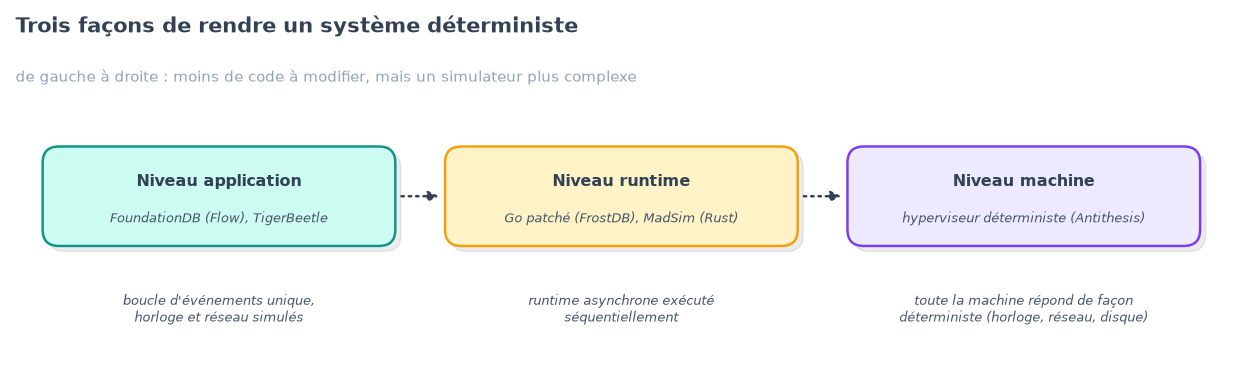

In [11]:
d = Diagram(13.5, 2.9, title="Trois façons de rendre un système déterministe",
            subtitle="de gauche à droite : moins de code à modifier, mais un simulateur plus complexe")
d.box("app", 2.3, 1.8, "Niveau application", sub="FoundationDB (Flow), TigerBeetle", color=TEAL, w=3.9, h=1.1)
d.box("rt", 6.75, 1.8, "Niveau runtime", sub="Go patché (FrostDB), MadSim (Rust)", color=AMBER, w=3.9, h=1.1)
d.box("mach", 11.2, 1.8, "Niveau machine", sub="hyperviseur déterministe (Antithesis)", color=VIOLET, w=3.9, h=1.1)
d.note(2.3, 0.55, "boucle d'événements unique,\nhorloge et réseau simulés", fontsize=8.5)
d.note(6.75, 0.55, "runtime asynchrone exécuté\nséquentiellement", fontsize=8.5)
d.note(11.2, 0.55, "toute la machine répond de façon\ndéterministe (horloge, réseau, disque)", fontsize=8.5)
d.arrow("app", "rt", style="dotted"); d.arrow("rt", "mach", style="dotted")
d.show()

Au-delà du rejeu, la DST a d'autres atouts. Antithesis ramifie une exécution en plusieurs
sous-exécutions quand il découvre un comportement rare. Et comme horloges et réseau sont
simulés, la simulation va **plus vite que le temps réel** : TigerBeetle simule des délais
et des expirations sans les attendre. Mesurons-le sur notre simulateur.

In [12]:
t0 = time.perf_counter()
n_runs = 100
for s in range(n_runs):
    dv.run_lease_system(dv.random_faults(s), seed=s)
mur = time.perf_counter() - t0
print(f"{n_runs} exécutions de 120 unités de temps simulé en {mur:.2f} s de temps réel : "
      f"environ {n_runs * 120 / mur:,.0f} unités simulées par seconde".replace(",", " "))

100 exécutions de 120 unités de temps simulé en 0.19 s de temps réel : environ 63 375 unités simulées par seconde


Si une unité représente une seconde, chaque seconde de calcul simule des heures de
fonctionnement du système, pannes comprises.

> **À retenir.** La simulation déterministe exécute le vrai code dans un monde simulé
> (réseau, horloges, pannes) piloté par une graine : on explore des milliers de scénarios
> plus vite que le temps réel, et tout échec se rejoue à l'identique, puis se réduit.

## 5. La puissance du déterminisme (encadré *The Power of Determinism*)

Le non-déterminisme est au cœur de tous les problèmes du chapitre : concurrence, délais
réseau, pauses, sauts d'horloge et pannes varient d'une exécution à l'autre. À l'inverse,
rendre un système **déterministe** simplifie énormément les choses, et l'idée revient
sans cesse :

- l'**event sourcing** rejoue un journal d'événements pour reconstruire des vues
  matérialisées (chapitres 3 et 12) ;
- les **moteurs de workflows** exigent des définitions de workflows déterministes pour
  offrir l'exécution durable (chapitre 5) ;
- la **réplication de machine à états** exécute la même suite de transactions
  déterministes sur chaque réplique (chapitre 10), comme la réplication
  par instructions (chapitre 6) ou l'exécution en série par procédures
  stockées (chapitre 8).

Rendre du code **totalement** déterministe demande du soin : même sans concurrence, avec
E/S, réseau, horloges et générateurs aléatoires simulés, il reste des pièges. Par
exemple, dans certains langages, l'ordre d'itération d'une table de hachage varie d'une
exécution à l'autre. C'est le cas des ensembles de chaînes en Python, dont le hachage est
salé aléatoirement à chaque lancement de l'interpréteur (sauf si `PYTHONHASHSEED` est
fixé) :

In [13]:
code = "print(list({'ananas', 'banane', 'cerise', 'datte', 'figue'}))"
rows = []
for graine in ["1", "2", "3", "1"]:
    env = dict(os.environ, PYTHONHASHSEED=graine)
    out = subprocess.run([sys.executable, "-c", code], env=env, capture_output=True, text=True).stdout.strip()
    rows.append(dict(PYTHONHASHSEED=graine, ordre_d_itération=out))
pd.DataFrame(rows)

,PYTHONHASHSEED,ordre_d_itération
0,1,"['cerise', 'datte', 'banane', 'ananas', 'figue']"
1,2,"['ananas', 'cerise', 'banane', 'datte', 'figue']"
2,3,"['banane', 'datte', 'ananas', 'figue', 'cerise']"
3,1,"['cerise', 'datte', 'banane', 'ananas', 'figue']"


Le même programme itère sur le même ensemble dans un ordre différent selon le sel du
hachage : un simulateur qui itérerait sur un ensemble de nœuds pour décider qui parle en
premier ne serait plus déterministe. (`ddia.sim` utilise des dictionnaires, ordonnés par
insertion, et un générateur aléatoire à graine.) Atteindre ou non une limite de ressources
(échec d'allocation, débordement de pile) est une autre source de non-déterminisme.

> **À retenir.** Le déterminisme est une idée simple et puissante : il rend les tests
> rejouables et fonde l'event sourcing, l'exécution durable et la réplication de machine à
> états. Mais il faut traquer toutes ses sources cachées.

## Synthèse

- L'espace des exécutions d'un système distribué est **astronomique** : il faut combiner
  raisonnement formel et exploration aléatoire.
- Un **model checker** explore tous les états d'un modèle borné et rend un contre-exemple
  minimal (le zombie, l'amnésie du service de verrous), mais il vérifie un modèle.
- L'**injection de fautes** (Jepsen, ingénierie du chaos) teste le vrai système, sans
  rejeu exact.
- La **simulation déterministe** teste le vrai code dans un monde simulé : exploration
  rapide, rejeu à l'identique, réduction des scénarios.

Liens : les propriétés de sûreté et de vivacité vérifiées ici sont celles du cours 5 ; le
chapitre 10 présente les algorithmes de consensus que ces techniques
servent à vérifier en pratique.